
# FIFA 20 Football Player Analysis and Clustering

**Project ID:** PRCP-1004-FIFA20

## 1. Problem Statement
Analyze FIFA 20 player data, investigate football skills and player
performance, and identify groups of players with similar skill profiles.

## 2. Project Objectives
- Perform data cleaning and exploratory data analysis.
- Rank the top 10 countries by player count.
- Analyze overall rating against player age.
- Compare wages of strikers, right-wingers, and left-wingers.
- Cluster players based on football skill attributes.
- Compare clustering algorithms using suitable metrics.
- Document findings, challenges, limitations, and recommendations.

## 3. Machine Learning Approach
Unsupervised learning using K-Means, Agglomerative Clustering,
and DBSCAN, subject to computational feasibility.

## 4. Expected Deliverables
- One complete Jupyter Notebook.
- Data analysis report.
- Clustering model comparison report.
- Data challenges and solutions report.
- Saved model and preprocessing artifacts.


In [113]:
# Import libraries

import os
import time
import json
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Libraries imported successfully.
Pandas version: 2.3.3
NumPy version: 2.3.5


In [114]:
# Load the dataset

df = pd.read_csv("players_20.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (18278, 104)


,sofifa_id,player_url,short_name,long_name,age,dob,height_cm,weight_kg,nationality,club,overall,potential,value_eur,wage_eur,player_positions,preferred_foot,international_reputation,weak_foot,skill_moves,work_rate,body_type,real_face,release_clause_eur,player_tags,team_position,team_jersey_number,loaned_from,joined,contract_valid_until,nation_position,nation_jersey_number,pace,shooting,passing,dribbling,defending,physic,gk_diving,gk_handling,gk_kicking,gk_reflexes,gk_speed,gk_positioning,player_traits,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,...,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,32,1987-06-24,170,72,Argentina,FC Barcelona,94,94,95500000,565000,"RW, CF, ST",Left,5,4,4,Medium/Low,Messi,Yes,"195,800,000.00","#Dribbler, #Distance Shooter, #Crosser, #FK Sp...",RW,10.00,NaN,2004-07-01,"2,021.00",NaN,NaN,87.00,92.00,92.00,96.00,39.00,66.00,NaN,NaN,NaN,NaN,NaN,NaN,"Beat Offside Trap, Argues with Officials, Earl...",88,95,70,92,88,97,...,91,84,93,95,95,86,68,75,68,94,48,40,94,94,75,96,33,37,26,6,11,15,14,8,89+2,89+2,89+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,92+2,87+2,87+2,87+2,92+2,68+2,66+2,66+2,66+2,68+2,63+2,52+2,52+2,52+2,63+2
1,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,34,1985-02-05,187,83,Portugal,Juventus,93,93,58500000,405000,"ST, LW",Right,5,4,5,High/Low,C. Ronaldo,Yes,"96,500,000.00","#Speedster, #Dribbler, #Distance Shooter, #Acr...",LW,7.00,NaN,2018-07-10,"2,022.00",LS,7.00,90.00,93.00,82.00,89.00,35.00,78.00,NaN,NaN,NaN,NaN,NaN,NaN,"Long Throw-in, Selfish, Argues with Officials,...",84,94,89,83,87,89,...,89,91,87,96,71,95,95,85,78,93,63,29,95,82,85,95,28,32,24,7,11,15,14,11,91+3,91+3,91+3,89+3,90+3,90+3,90+3,89+3,88+3,88+3,88+3,88+3,81+3,81+3,81+3,88+3,65+3,61+3,61+3,61+3,65+3,61+3,53+3,53+3,53+3,61+3
2,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Junior,27,1992-02-05,175,68,Brazil,Paris Saint-Germain,92,92,105500000,290000,"LW, CAM",Right,5,5,5,High/Medium,Neymar,Yes,"195,200,000.00","#Speedster, #Dribbler, #Playmaker , #Crosser,...",CAM,10.00,NaN,2017-08-03,"2,022.00",LW,10.00,91.00,85.00,87.00,95.00,32.00,58.00,NaN,NaN,NaN,NaN,NaN,NaN,"Power Free-Kick, Injury Free, Selfish, Early C...",87,87,62,87,87,96,...,94,89,96,92,84,80,61,81,49,84,51,36,87,90,90,94,27,26,29,9,9,15,15,11,84+3,84+3,84+3,90+3,89+3,89+3,89+3,90+3,90+3,90+3,90+3,89+3,82+3,82+3,82+3,89+3,66+3,61+3,61+3,61+3,66+3,61+3,46+3,46+3,46+3,61+3
3,200389,https://sofifa.com/player/200389/jan-oblak/20/...,J. Oblak,Jan Oblak,26,1993-01-07,188,87,Slovenia,Atlético Madrid,91,93,77500000,125000,GK,Right,3,3,1,Medium/Medium,Normal,Yes,"164,700,000.00",NaN,GK,13.00,NaN,2014-07-16,"2,023.00",GK,1.00,NaN,NaN,NaN,NaN,NaN,NaN,87.00,92.00,78.00,89.00,52.00,90.00,"Flair, Acrobatic Clearance",13,11,15,43,13,12,...,43,60,67,88,49,59,78,41,78,12,34,19,11,65,11,68,27,12,18,87,92,78,90,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,183277,https://sofifa.com/player/183277/eden-hazard/2...,E. Hazard,Eden Hazard,28,1991-01-07,175,74,Belgium,Real Madrid,91,91,90000000,470000,"LW, CF",Right,4,4,4,High/Medium,Normal,Yes,"184,500,000.00","#Speedster, #Dribbler, #Acrobat",LW,7.00,NaN,2019-07-01,"2,024.00",LF,10.00,91.

In [115]:
# Understand the dataset

print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five records:")
display(df.head())

print("\nRandom five records:")
display(df.sample(min(5, len(df)), random_state=RANDOM_STATE))


Dataset dimensions: (18278, 104)

Column names:
['sofifa_id', 'player_url', 'short_name', 'long_name', 'age', 'dob', 'height_cm', 'weight_kg', 'nationality', 'club', 'overall', 'potential', 'value_eur', 'wage_eur', 'player_positions', 'preferred_foot', 'international_reputation', 'weak_foot', 'skill_moves', 'work_rate', 'body_type', 'real_face', 'release_clause_eur', 'player_tags', 'team_position', 'team_jersey_number', 'loaned_from', 'joined', 'contract_valid_until', 'nation_position', 'nation_jersey_number', 'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'gk_diving', 'gk_handling', 'gk_kicking', 'gk_reflexes', 'gk_speed', 'gk_positioning', 'player_traits', 'attacking_crossing', 'attacking_finishing', 'attacking_heading_accuracy', 'attacking_short_passing', 'attacking_volleys', 'skill_dribbling', 'skill_curve', 'skill_fk_accuracy', 'skill_long_passing', 'skill_ball_control', 'movement_acceleration', 'movement_sprint_speed', 'movement_agility', 'movement_reactions',

,sofifa_id,player_url,short_name,long_name,age,dob,height_cm,weight_kg,nationality,club,overall,potential,value_eur,wage_eur,player_positions,preferred_foot,international_reputation,weak_foot,skill_moves,work_rate,body_type,real_face,release_clause_eur,player_tags,team_position,team_jersey_number,loaned_from,joined,contract_valid_until,nation_position,nation_jersey_number,pace,shooting,passing,dribbling,defending,physic,gk_diving,gk_handling,gk_kicking,gk_reflexes,gk_speed,gk_positioning,player_traits,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,...,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,32,1987-06-24,170,72,Argentina,FC Barcelona,94,94,95500000,565000,"RW, CF, ST",Left,5,4,4,Medium/Low,Messi,Yes,"195,800,000.00","#Dribbler, #Distance Shooter, #Crosser, #FK Sp...",RW,10.00,NaN,2004-07-01,"2,021.00",NaN,NaN,87.00,92.00,92.00,96.00,39.00,66.00,NaN,NaN,NaN,NaN,NaN,NaN,"Beat Offside Trap, Argues with Officials, Earl...",88,95,70,92,88,97,...,91,84,93,95,95,86,68,75,68,94,48,40,94,94,75,96,33,37,26,6,11,15,14,8,89+2,89+2,89+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,92+2,87+2,87+2,87+2,92+2,68+2,66+2,66+2,66+2,68+2,63+2,52+2,52+2,52+2,63+2
1,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,34,1985-02-05,187,83,Portugal,Juventus,93,93,58500000,405000,"ST, LW",Right,5,4,5,High/Low,C. Ronaldo,Yes,"96,500,000.00","#Speedster, #Dribbler, #Distance Shooter, #Acr...",LW,7.00,NaN,2018-07-10,"2,022.00",LS,7.00,90.00,93.00,82.00,89.00,35.00,78.00,NaN,NaN,NaN,NaN,NaN,NaN,"Long Throw-in, Selfish, Argues with Officials,...",84,94,89,83,87,89,...,89,91,87,96,71,95,95,85,78,93,63,29,95,82,85,95,28,32,24,7,11,15,14,11,91+3,91+3,91+3,89+3,90+3,90+3,90+3,89+3,88+3,88+3,88+3,88+3,81+3,81+3,81+3,88+3,65+3,61+3,61+3,61+3,65+3,61+3,53+3,53+3,53+3,61+3
2,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Junior,27,1992-02-05,175,68,Brazil,Paris Saint-Germain,92,92,105500000,290000,"LW, CAM",Right,5,5,5,High/Medium,Neymar,Yes,"195,200,000.00","#Speedster, #Dribbler, #Playmaker , #Crosser,...",CAM,10.00,NaN,2017-08-03,"2,022.00",LW,10.00,91.00,85.00,87.00,95.00,32.00,58.00,NaN,NaN,NaN,NaN,NaN,NaN,"Power Free-Kick, Injury Free, Selfish, Early C...",87,87,62,87,87,96,...,94,89,96,92,84,80,61,81,49,84,51,36,87,90,90,94,27,26,29,9,9,15,15,11,84+3,84+3,84+3,90+3,89+3,89+3,89+3,90+3,90+3,90+3,90+3,89+3,82+3,82+3,82+3,89+3,66+3,61+3,61+3,61+3,66+3,61+3,46+3,46+3,46+3,61+3
3,200389,https://sofifa.com/player/200389/jan-oblak/20/...,J. Oblak,Jan Oblak,26,1993-01-07,188,87,Slovenia,Atlético Madrid,91,93,77500000,125000,GK,Right,3,3,1,Medium/Medium,Normal,Yes,"164,700,000.00",NaN,GK,13.00,NaN,2014-07-16,"2,023.00",GK,1.00,NaN,NaN,NaN,NaN,NaN,NaN,87.00,92.00,78.00,89.00,52.00,90.00,"Flair, Acrobatic Clearance",13,11,15,43,13,12,...,43,60,67,88,49,59,78,41,78,12,34,19,11,65,11,68,27,12,18,87,92,78,90,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,183277,https://sofifa.com/player/183277/eden-hazard/2...,E. Hazard,Eden Hazard,28,1991-01-07,175,74,Belgium,Real Madrid,91,91,90000000,470000,"LW, CF",Right,4,4,4,High/Medium,Normal,Yes,"184,500,000.00","#Speedster, #Dribbler, #Acrobat",LW,7.00,NaN,2019-07-01,"2,024.00",LF,10.00,91.


Random five records:


,sofifa_id,player_url,short_name,long_name,age,dob,height_cm,weight_kg,nationality,club,overall,potential,value_eur,wage_eur,player_positions,preferred_foot,international_reputation,weak_foot,skill_moves,work_rate,body_type,real_face,release_clause_eur,player_tags,team_position,team_jersey_number,loaned_from,joined,contract_valid_until,nation_position,nation_jersey_number,pace,shooting,passing,dribbling,defending,physic,gk_diving,gk_handling,gk_kicking,gk_reflexes,gk_speed,gk_positioning,player_traits,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,...,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb
11854,165502,https://sofifa.com/player/165502/josh-lillis/2...,J. Lillis,Josh Lillis,32,1987-06-24,183,79,England,Rochdale,64,64,270000,1000,GK,Right,1,2,1,Medium/Medium,Normal,No,"473,000.00",NaN,SUB,1.00,NaN,2012-06-01,"2,020.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,66.00,63.00,62.00,66.00,44.00,57.00,"Power Free-Kick, Flair, Second Wind",14,14,15,27,11,15,...,46,42,52,62,57,47,68,40,68,13,39,23,13,24,14,60,18,17,17,66,63,62,57,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2647,245850,https://sofifa.com/player/245850/ibrahim-traor...,I. Traoré,Ibrahim Traoré,30,1988-09-16,186,80,Ivory Coast,SK Slavia Praha,74,74,5000000,1000,"CM, CAM, CDM",Right,1,3,3,Medium/Medium,Normal,No,"11,000,000.00",NaN,SUB,27.00,NaN,2019-01-01,"2,022.00",NaN,NaN,72.00,61.00,69.00,74.00,70.00,81.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65,61,70,73,58,75,...,71,72,70,74,73,58,76,84,82,60,76,70,71,72,61,76,67,72,68,8,11,13,10,14,68+2,68+2,68+2,70+2,70+2,70+2,70+2,70+2,71+2,71+2,71+2,72+2,72+2,72+2,72+2,72+2,71+2,72+2,72+2,72+2,71+2,71+2,72+2,72+2,72+2,71+2
5945,229692,https://sofifa.com/player/229692/jannik-huth/2...,J. Huth,Jannik Huth,25,1994-04-15,185,80,Germany,SC Paderborn 07,69,74,1000000,8000,GK,Right,1,4,1,Medium/Medium,Normal,No,"1,900,000.00",NaN,GK,21.00,NaN,2019-07-01,"2,022.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.00,65.00,74.00,72.00,55.00,66.00,Second Wind,17,16,10,33,15,22,...,54,55,50,66,44,56,74,32,63,14,28,25,20,42,24,41,22,14,11,70,65,74,66,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6798,241025,https://sofifa.com/player/241025/leonardo-here...,L. Heredia,Leonardo Matías Heredia,22,1996-10-11,185,79,Argentina,Atlético Tucumán,68,76,1300000,5000,"RM, CAM, CM",Right,1,4,3,High/Medium,Normal,No,"2,200,000.00",NaN,SUB,17.00,NaN,2019-07-03,"2,022.00",NaN,NaN,72.00,64.00,64.00,70.00,34.00,67.00,NaN,NaN,NaN,NaN,NaN,NaN,"Selfish, Crowd Favourite",64,62,58,66,71,72,...,70,73,67,62,54,71,61,66,72,63,56,33,65,65,56,57,32,31,30,11,8,13,8,8,66+2,66+2,66+2,67+2,66+2,66+2,66+2,67+2,66+2,66+2,66+2,67+2,62+2,62+2,62+2,67+2,53+2,51+2,51+2,51+2,53+2,50+2,46+2,46+2,46+2,50+2
12985,202295,https://sofifa.com/player/202295/gi-dong-park/...,Park Gi Dong,박기동 朴基栋,30,1988-11-01,191,83,Korea Republic,Daegu FC,63,63,350000,2000,ST,Right,1,5,2,Medium/Low,Normal,No,NaN,NaN,SUB,22.00,Gyeongnam FC,NaN,"2,019.00",NaN,NaN,59.00,59.00,54.00,59.00,29.00,71.00,NaN,NaN,NaN,NaN,NaN,NaN,Power Free-Kick,40,58,67,64,56,58,...,53,63,57,58,53,62,52,71,77,56,63,36,65,57,62,62,21,23,22,14,7,13,8,8,61+2,61+2,61+2,58+2,60+2,60+2,60+2,58+2,59+2,59+2,59+2,57+2,56+2,56+2,56+2,57+2,46+2,47+2,47+2,47+2,46+2,44+2,43+2,43+2,43+2,44+2


In [116]:
# Code: Statistical summary

print("Numerical feature summary:")
display(df.describe().T)

print("\nCategorical feature summary:")
display(df.describe(include=["object", "category"]).T)

Numerical feature summary:


,count,mean,std,min,25%,50%,75%,max
sofifa_id,"18,278.00","219,738.86","27,960.20",768.00,"204,445.50","226,165.00","240,795.75","252,905.00"
age,"18,278.00",25.28,4.66,16.00,22.00,25.00,29.00,42.00
height_cm,"18,278.00",181.36,6.76,156.00,177.00,181.00,186.00,205.00
weight_kg,"18,278.00",75.28,7.05,50.00,70.00,75.00,80.00,110.00
overall,"18,278.00",66.24,6.95,48.00,62.00,66.00,71.00,94.00
potential,"18,278.00",71.55,6.14,49.00,67.00,71.00,75.00,95.00
value_eur,"18,278.00","2,484,037.64","5,585,481.06",0.00,"325,000.00","700,000.00","2,100,000.00","105,500,000.00"
wage_eur,"18,278.00","9,456.94","21,351.71",0.00,"1,000.00","3,000.00","8,000.00","565,000.00"
international_reputation,"18,278.00",1.10,0.38,1.00,1.00,1.00,1.00,5.00
weak_foot,"18,278.00",2.94,0.66,1.00,3.00,3.00,3.00,5.00



Categorical feature summary:


,count,unique,top,freq
player_url,18278,18278,https://sofifa.com/player/158023/lionel-messi/...,1
short_name,18278,17354,J. Rodríguez,11
long_name,18278,18218,Liam Kelly,3
dob,18278,6142,1992-02-29,113
nationality,18278,162,England,1667
club,18278,698,FC Barcelona,33
player_positions,18278,643,CB,2322
preferred_foot,18278,2,Right,13960
work_rate,18278,9,Medium/Medium,9875
body_type,18278,10,Normal,10750


In [117]:
# Summarizes numeric and categorical data separately.

In [118]:
# Standardize column names

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

print("Column names standardized.")
print(df.columns.tolist())

Column names standardized.
['sofifa_id', 'player_url', 'short_name', 'long_name', 'age', 'dob', 'height_cm', 'weight_kg', 'nationality', 'club', 'overall', 'potential', 'value_eur', 'wage_eur', 'player_positions', 'preferred_foot', 'international_reputation', 'weak_foot', 'skill_moves', 'work_rate', 'body_type', 'real_face', 'release_clause_eur', 'player_tags', 'team_position', 'team_jersey_number', 'loaned_from', 'joined', 'contract_valid_until', 'nation_position', 'nation_jersey_number', 'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'gk_diving', 'gk_handling', 'gk_kicking', 'gk_reflexes', 'gk_speed', 'gk_positioning', 'player_traits', 'attacking_crossing', 'attacking_finishing', 'attacking_heading_accuracy', 'attacking_short_passing', 'attacking_volleys', 'skill_dribbling', 'skill_curve', 'skill_fk_accuracy', 'skill_long_passing', 'skill_ball_control', 'movement_acceleration', 'movement_sprint_speed', 'movement_agility', 'movement_reactions', 'movement_balance', 

### Create a reusable data quality report

In [119]:
# quality-report function

def generate_data_quality_report(data: pd.DataFrame) -> pd.DataFrame:
    """
    Generate a column-level data quality report.

    Parameters
    ----------
    data : pd.DataFrame
        Dataset to inspect.

    Returns
    -------
    pd.DataFrame
        Data types, missing counts, missing percentages,
        unique counts, and duplicate-value counts.
    """
    if not isinstance(data, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame.")

    report = pd.DataFrame({
        "Data_Type": data.dtypes.astype(str),
        "Missing_Count": data.isna().sum(),
        "Missing_Percentage": (
            data.isna().mean() * 100
        ).round(2),
        "Unique_Values": data.nunique(dropna=True)
    })

    report.index.name = "Feature"

    return report.sort_values(
        "Missing_Percentage",
        ascending=False
    )


quality_report = generate_data_quality_report(df)

display(quality_report)

,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
Feature,,,,
loaned_from,object,17230,94.27,316
nation_position,object,17152,93.84,26
nation_jersey_number,float64,17152,93.84,30
player_tags,object,16779,91.80,83
gk_speed,float64,16242,88.86,53
...,...,...,...,...
attacking_volleys,int64,0,0.00,87
attacking_short_passing,int64,0,0.00,84
attacking_heading_accuracy,int64,0,0.00,89


In [120]:
# A table sorted by missing-value percentage.

In [121]:
# Inspect duplicate records

print("Exact duplicate rows:", df.duplicated().sum())

if "sofifa_id" in df.columns:
    print(
        "Rows with repeated player IDs:",
        df["sofifa_id"].duplicated().sum()
    )

if "short_name" in df.columns:
    print(
        "Rows with repeated short names:",
        df["short_name"].duplicated().sum()
    )

Exact duplicate rows: 0
Rows with repeated player IDs: 0
Rows with repeated short names: 924


In [122]:
# Duplicate counts for the available columns.

### Clean the data

In [123]:
# Remove exact duplicates

rows_before = len(df)

df = df.drop_duplicates().copy()

rows_removed = rows_before - len(df)

print(f"Rows before cleaning: {rows_before:,}")
print(f"Exact duplicate rows removed: {rows_removed:,}")
print(f"Rows after cleaning: {len(df):,}")

Rows before cleaning: 18,278
Exact duplicate rows removed: 0
Rows after cleaning: 18,278


In [124]:
# The number of rows removed and the new dataset size.

In [125]:
# Validate important columns

required_columns = ["age", "overall", "nationality"]

missing_required = [
    column for column in required_columns
    if column not in df.columns
]

if missing_required:
    print("Required columns not found:", missing_required)
    print("Review the actual column names before continuing.")
else:
    print("Required analysis columns are available.")

print("\nPosition-related columns:")
print([
    column for column in df.columns
    if "position" in column
])

print("\nWage-related columns:")
print([
    column for column in df.columns
    if "wage" in column
])

Required analysis columns are available.

Position-related columns:
['player_positions', 'team_position', 'nation_position', 'gk_positioning', 'mentality_positioning', 'goalkeeping_positioning']

Wage-related columns:
['wage_eur']


In [126]:
# A confirmation or a list of columns that need attention.

In [127]:
# Inspect missing values in key columns

key_columns = [
    "short_name",
    "age",
    "nationality",
    "overall",
    "potential",
    "wage_eur",
    "value_eur",
    "player_positions"
]

available_key_columns = [
    column for column in key_columns
    if column in df.columns
]

display(
    df[available_key_columns]
    .isna()
    .sum()
    .rename("Missing_Count")
    .to_frame()
)

,Missing_Count
Feature,
short_name,0
age,0
nationality,0
overall,0
potential,0
wage_eur,0
value_eur,0
player_positions,0


In [128]:
# Validate numeric ranges

numeric_checks = [
    "age",
    "overall",
    "potential",
    "wage_eur",
    "value_eur",
    "height_cm",
    "weight_kg"
]

for column in numeric_checks:
    if column in df.columns:
        print(f"\n--- {column} ---")
        print(df[column].describe())
        print("Negative values:", (df[column] < 0).sum())


--- age ---
count   18,278.00
mean        25.28
std          4.66
min         16.00
25%         22.00
50%         25.00
75%         29.00
max         42.00
Name: age, dtype: float64
Negative values: 0

--- overall ---
count   18,278.00
mean        66.24
std          6.95
min         48.00
25%         62.00
50%         66.00
75%         71.00
max         94.00
Name: overall, dtype: float64
Negative values: 0

--- potential ---
count   18,278.00
mean        71.55
std          6.14
min         49.00
25%         67.00
50%         71.00
75%         75.00
max         95.00
Name: potential, dtype: float64
Negative values: 0

--- wage_eur ---
count    18,278.00
mean      9,456.94
std      21,351.71
min           0.00
25%       1,000.00
50%       3,000.00
75%       8,000.00
max     565,000.00
Name: wage_eur, dtype: float64
Negative values: 0

--- value_eur ---
count        18,278.00
mean      2,484,037.64
std       5,585,481.06
min               0.00
25%         325,000.00
50%         700,000.

In [129]:
# Create a cleaned analysis dataset

df_clean = df.copy()

# Remove rows without usable player names only when the
# dataset contains the corresponding field.
if "short_name" in df_clean.columns:
    rows_before = len(df_clean)
    df_clean = df_clean.dropna(subset=["short_name"]).copy()
    print(
        "Rows removed due to missing player name:",
        rows_before - len(df_clean)
    )

print("Cleaned dataset shape:", df_clean.shape)
display(df_clean.head())

Rows removed due to missing player name: 0
Cleaned dataset shape: (18278, 104)


Feature,sofifa_id,player_url,short_name,long_name,age,dob,height_cm,weight_kg,nationality,club,overall,potential,value_eur,wage_eur,player_positions,preferred_foot,international_reputation,weak_foot,skill_moves,work_rate,body_type,real_face,release_clause_eur,player_tags,team_position,team_jersey_number,loaned_from,joined,contract_valid_until,nation_position,nation_jersey_number,pace,shooting,passing,dribbling,defending,physic,gk_diving,gk_handling,gk_kicking,gk_reflexes,gk_speed,gk_positioning,player_traits,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,...,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,32,1987-06-24,170,72,Argentina,FC Barcelona,94,94,95500000,565000,"RW, CF, ST",Left,5,4,4,Medium/Low,Messi,Yes,"195,800,000.00","#Dribbler, #Distance Shooter, #Crosser, #FK Sp...",RW,10.00,NaN,2004-07-01,"2,021.00",NaN,NaN,87.00,92.00,92.00,96.00,39.00,66.00,NaN,NaN,NaN,NaN,NaN,NaN,"Beat Offside Trap, Argues with Officials, Earl...",88,95,70,92,88,97,...,91,84,93,95,95,86,68,75,68,94,48,40,94,94,75,96,33,37,26,6,11,15,14,8,89+2,89+2,89+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,92+2,87+2,87+2,87+2,92+2,68+2,66+2,66+2,66+2,68+2,63+2,52+2,52+2,52+2,63+2
1,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,34,1985-02-05,187,83,Portugal,Juventus,93,93,58500000,405000,"ST, LW",Right,5,4,5,High/Low,C. Ronaldo,Yes,"96,500,000.00","#Speedster, #Dribbler, #Distance Shooter, #Acr...",LW,7.00,NaN,2018-07-10,"2,022.00",LS,7.00,90.00,93.00,82.00,89.00,35.00,78.00,NaN,NaN,NaN,NaN,NaN,NaN,"Long Throw-in, Selfish, Argues with Officials,...",84,94,89,83,87,89,...,89,91,87,96,71,95,95,85,78,93,63,29,95,82,85,95,28,32,24,7,11,15,14,11,91+3,91+3,91+3,89+3,90+3,90+3,90+3,89+3,88+3,88+3,88+3,88+3,81+3,81+3,81+3,88+3,65+3,61+3,61+3,61+3,65+3,61+3,53+3,53+3,53+3,61+3
2,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Junior,27,1992-02-05,175,68,Brazil,Paris Saint-Germain,92,92,105500000,290000,"LW, CAM",Right,5,5,5,High/Medium,Neymar,Yes,"195,200,000.00","#Speedster, #Dribbler, #Playmaker , #Crosser,...",CAM,10.00,NaN,2017-08-03,"2,022.00",LW,10.00,91.00,85.00,87.00,95.00,32.00,58.00,NaN,NaN,NaN,NaN,NaN,NaN,"Power Free-Kick, Injury Free, Selfish, Early C...",87,87,62,87,87,96,...,94,89,96,92,84,80,61,81,49,84,51,36,87,90,90,94,27,26,29,9,9,15,15,11,84+3,84+3,84+3,90+3,89+3,89+3,89+3,90+3,90+3,90+3,90+3,89+3,82+3,82+3,82+3,89+3,66+3,61+3,61+3,61+3,66+3,61+3,46+3,46+3,46+3,61+3
3,200389,https://sofifa.com/player/200389/jan-oblak/20/...,J. Oblak,Jan Oblak,26,1993-01-07,188,87,Slovenia,Atlético Madrid,91,93,77500000,125000,GK,Right,3,3,1,Medium/Medium,Normal,Yes,"164,700,000.00",NaN,GK,13.00,NaN,2014-07-16,"2,023.00",GK,1.00,NaN,NaN,NaN,NaN,NaN,NaN,87.00,92.00,78.00,89.00,52.00,90.00,"Flair, Acrobatic Clearance",13,11,15,43,13,12,...,43,60,67,88,49,59,78,41,78,12,34,19,11,65,11,68,27,12,18,87,92,78,90,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,183277,https://sofifa.com/player/183277/eden-hazard/2...,E. Hazard,Eden Hazard,28,1991-01-07,175,74,Belgium,Real Madrid,91,91,90000000,470000,"LW, CF",Right,4,4,4,High/Medium,Normal,Yes,"184,500,000.00","#Speedster, #Dribbler, #Acrobat",LW,7.00,NaN,2019-07-01,"2,024.00",LF,10


# Exploratory Data Analysis (EDA)

This section investigates player demographics, football skills,
overall ratings, wages, player positions, and relationships
between important attributes.


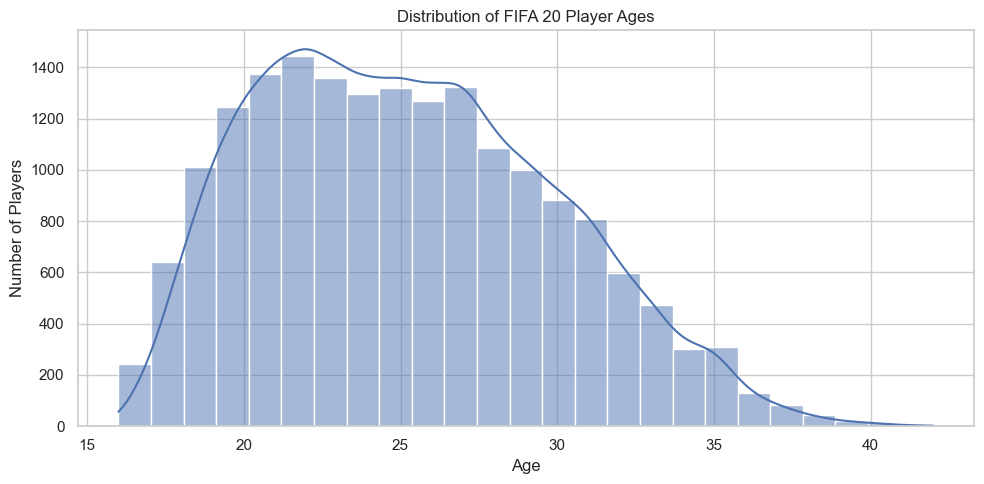

count   18,278.00
mean        25.28
std          4.66
min         16.00
25%         22.00
50%         25.00
75%         29.00
max         42.00
Name: age, dtype: float64


In [130]:
# Player age distribution

if "age" in df_clean.columns:
    age_data = pd.to_numeric(df_clean["age"], errors="coerce").dropna()

    plt.figure(figsize=(10, 5))
    sns.histplot(age_data, bins=25, kde=True)
    plt.title("Distribution of FIFA 20 Player Ages")
    plt.xlabel("Age")
    plt.ylabel("Number of Players")
    plt.tight_layout()
    plt.show()

    print(age_data.describe())
else:
    print("Age column is unavailable.")


In [131]:
# A histogram with a density curve.

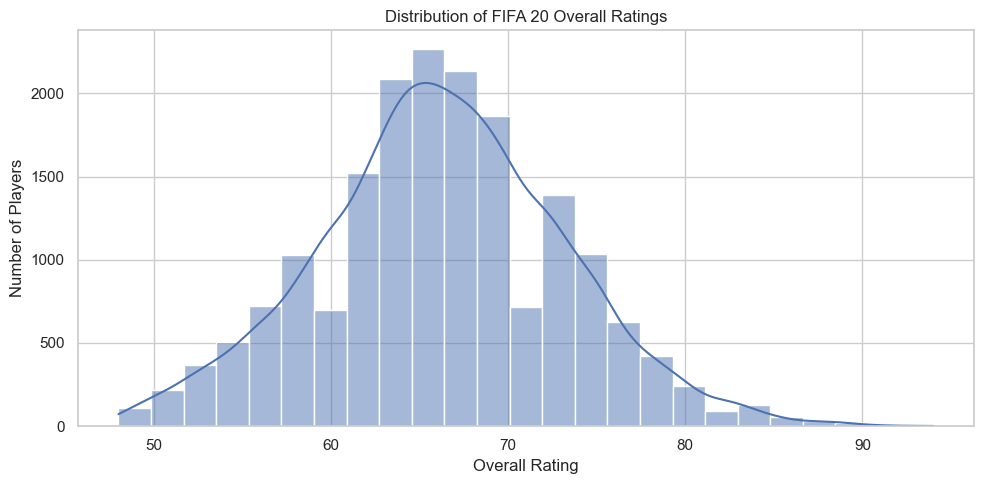

Mean overall rating: 66.24
Median overall rating: 66.0


In [132]:
# Overall rating distribution

if "overall" in df_clean.columns:
    overall_data = pd.to_numeric(
        df_clean["overall"], errors="coerce"
    ).dropna()

    plt.figure(figsize=(10, 5))
    sns.histplot(overall_data, bins=25, kde=True)
    plt.title("Distribution of FIFA 20 Overall Ratings")
    plt.xlabel("Overall Rating")
    plt.ylabel("Number of Players")
    plt.tight_layout()
    plt.show()

    print("Mean overall rating:", round(overall_data.mean(), 2))
    print("Median overall rating:", round(overall_data.median(), 2))
else:
    print("Overall column is unavailable.")


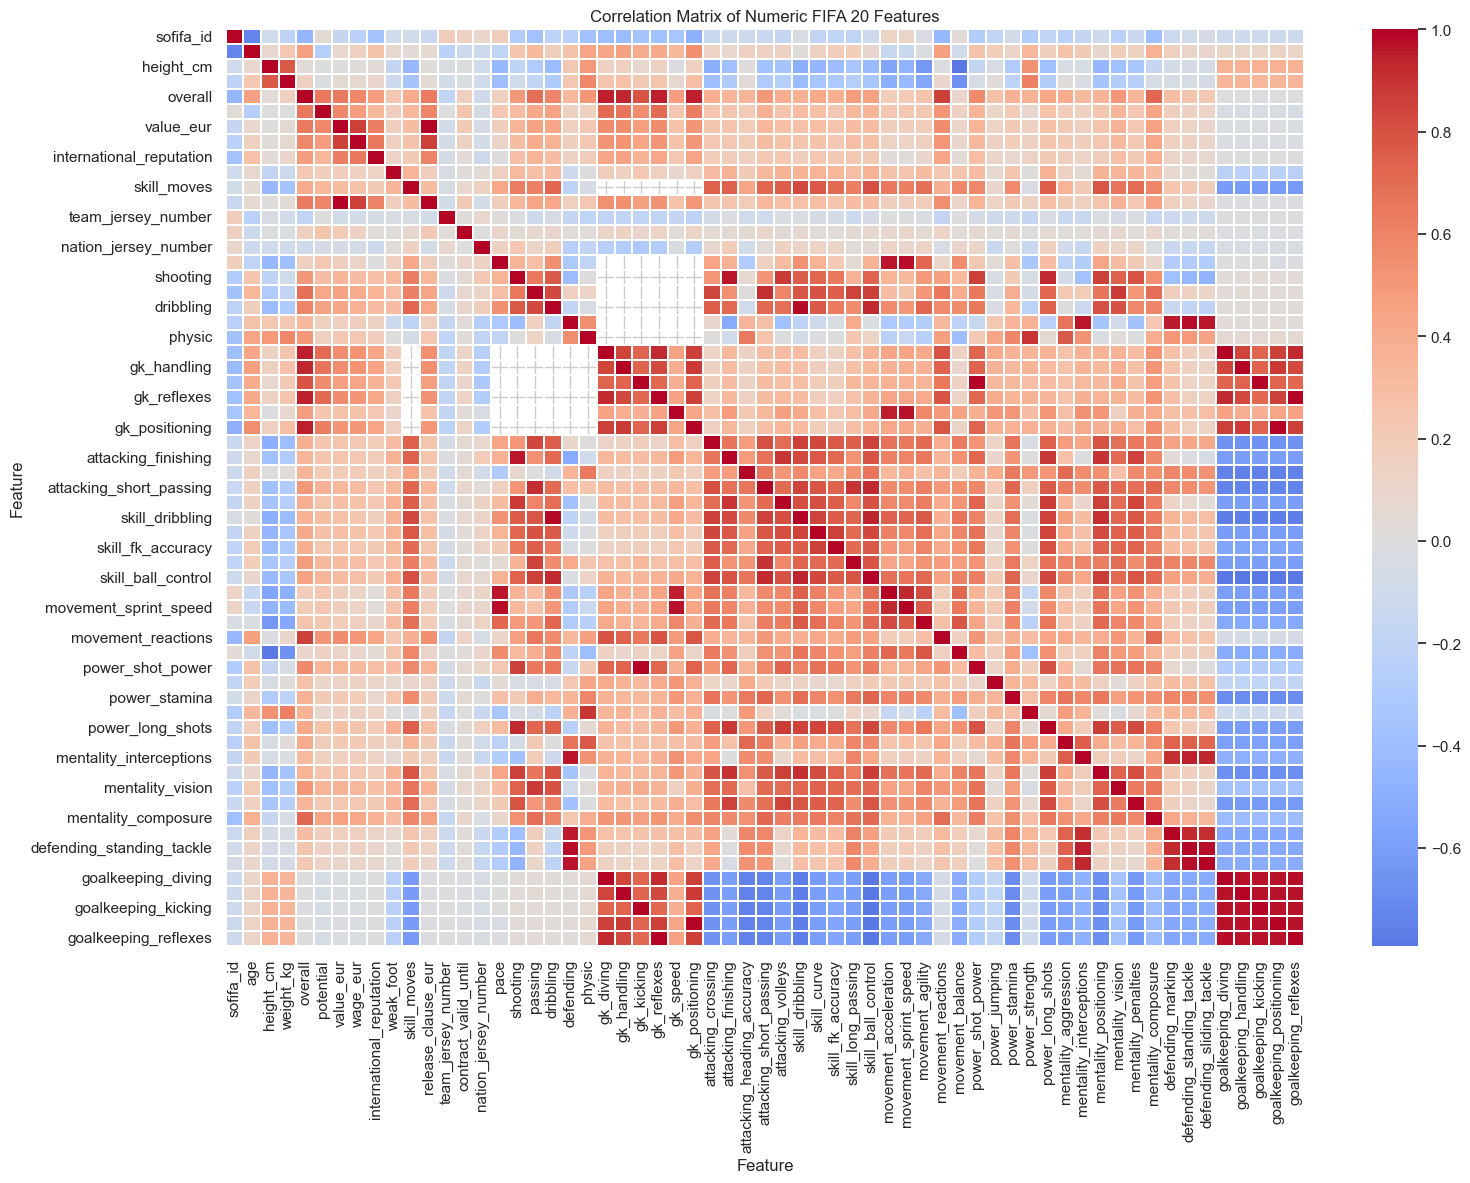

In [133]:
# Correlation heatmap

numeric_df = df_clean.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:
    correlation_matrix = numeric_df.corr()

    plt.figure(figsize=(16, 12))
    sns.heatmap(
        correlation_matrix,
        cmap="coolwarm",
        center=0,
        linewidths=0.2
    )
    plt.title("Correlation Matrix of Numeric FIFA 20 Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for correlation analysis.")

In [134]:
# Reveals relationships among numeric features. Correlation does not imply causation.

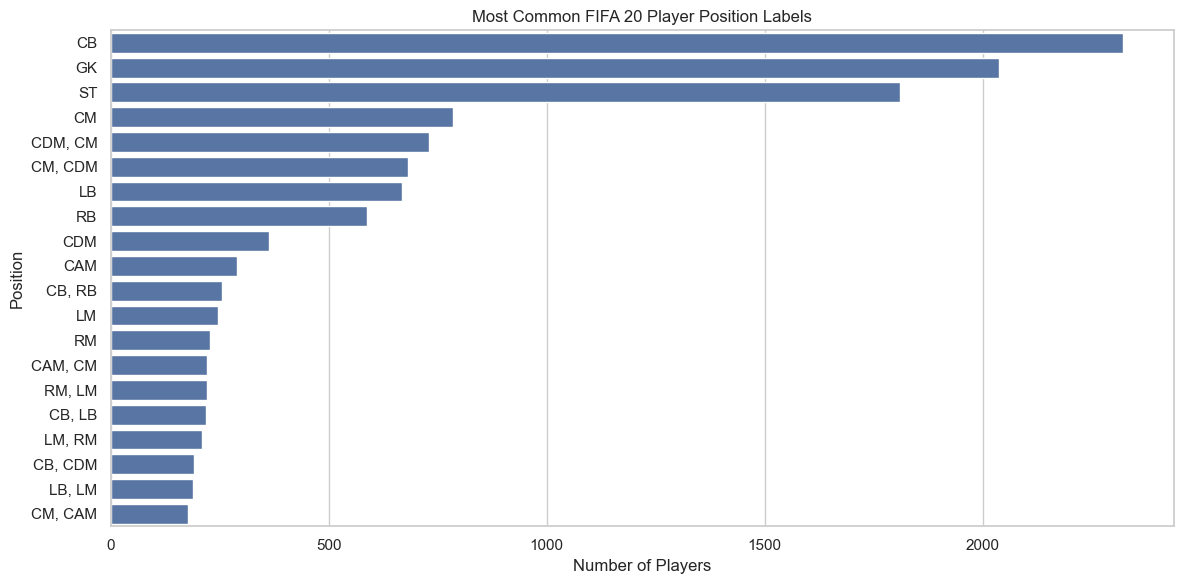

,Player_Count
player_positions,
CB,2322
GK,2036
ST,1809
CM,786
"CDM, CM",731
"CM, CDM",682
LB,669
RB,587
CDM,363


In [135]:
# Inspect player positions

position_column = next(
    (
        column for column in
        ["player_positions", "position", "team_position"]
        if column in df_clean.columns
    ),
    None
)

if position_column:
    position_counts = (
        df_clean[position_column]
        .dropna()
        .astype(str)
        .value_counts()
        .head(20)
    )

    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=position_counts.values,
        y=position_counts.index
    )
    plt.title("Most Common FIFA 20 Player Position Labels")
    plt.xlabel("Number of Players")
    plt.ylabel("Position")
    plt.tight_layout()
    plt.show()

    display(position_counts.to_frame("Player_Count"))
else:
    print("No recognized position column was found.")

,Rank,Country,Player_Count
0,1,England,1667
1,2,Germany,1216
2,3,Spain,1035
3,4,France,984
4,5,Argentina,886
5,6,Brazil,824
6,7,Italy,732
7,8,Colombia,591
8,9,Japan,453
9,10,Netherlands,416


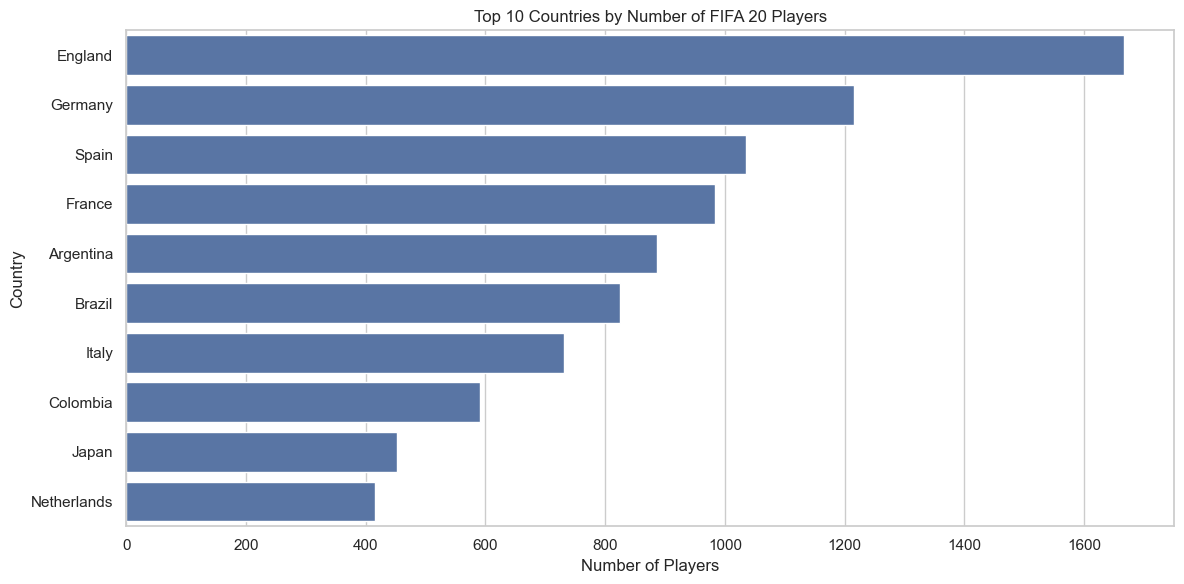

In [136]:
# Top 10 countries by player count

country_column = next(
    (
        column for column in
        ["nationality", "country"]
        if column in df_clean.columns
    ),
    None
)

if country_column is None:
    print("Country or nationality column not found.")
else:
    country_counts = (
        df_clean[country_column]
        .dropna()
        .value_counts()
        .head(10)
        .rename_axis("Country")
        .reset_index(name="Player_Count")
    )

    country_counts.insert(
        0, "Rank", range(1, len(country_counts) + 1)
    )

    display(country_counts)

    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=country_counts,
        x="Player_Count",
        y="Country"
    )
    plt.title("Top 10 Countries by Number of FIFA 20 Players")
    plt.xlabel("Number of Players")
    plt.ylabel("Country")
    plt.tight_layout()
    plt.show()

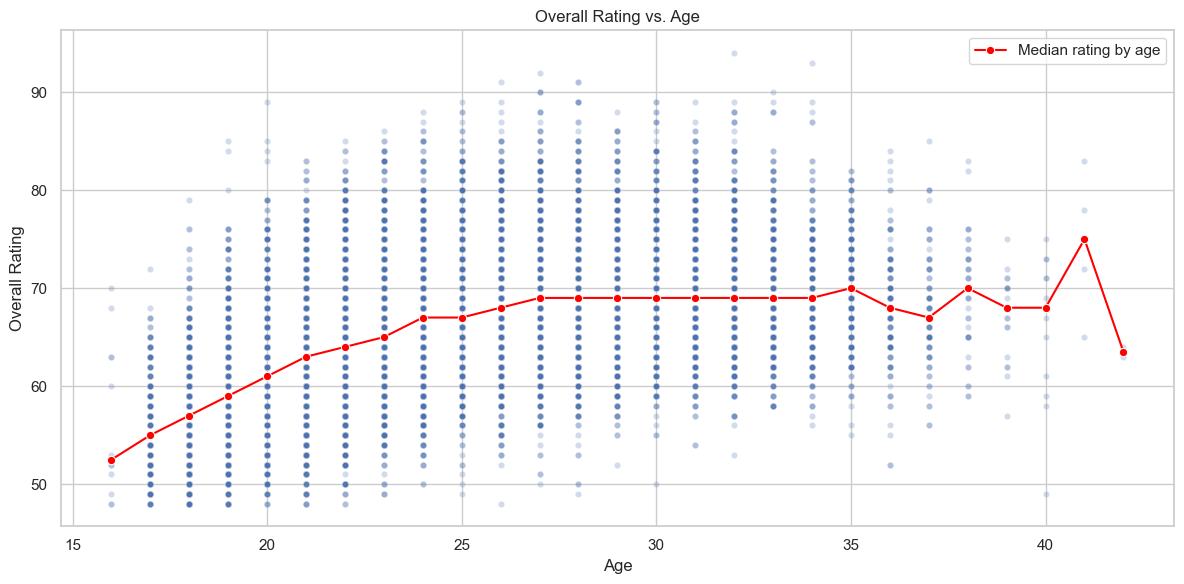

,age,overall
0,16,52.50
1,17,55.00
2,18,57.00
3,19,59.00
4,20,61.00
5,21,63.00
6,22,64.00
7,23,65.00
8,24,67.00
9,25,67.00


Age with highest median overall rating: 41


In [137]:
# Overall rating versus age

required = {"age", "overall"}

if required.issubset(df_clean.columns):
    age_rating = df_clean[["age", "overall"]].copy()

    age_rating["age"] = pd.to_numeric(
        age_rating["age"], errors="coerce"
    )
    age_rating["overall"] = pd.to_numeric(
        age_rating["overall"], errors="coerce"
    )

    age_rating = age_rating.dropna()

    plt.figure(figsize=(12, 6))
    sns.scatterplot(
        data=age_rating,
        x="age",
        y="overall",
        alpha=0.25,
        s=20
    )

    age_median = (
        age_rating.groupby("age")["overall"]
        .median()
        .reset_index()
    )

    sns.lineplot(
        data=age_median,
        x="age",
        y="overall",
        marker="o",
        color="red",
        label="Median rating by age"
    )

    plt.title("Overall Rating vs. Age")
    plt.xlabel("Age")
    plt.ylabel("Overall Rating")
    plt.legend()
    plt.tight_layout()
    plt.show()

    display(age_median)

    peak_age = age_median.loc[
        age_median["overall"].idxmax(), "age"
    ]
    print("Age with highest median overall rating:", peak_age)
else:
    print("Required age or overall column not found.")


,count,mean,median
Offensive_Group,,,
Striker,2582,"10,152.59","4,000.00"
Left Winger,378,"14,037.04","3,000.00"
Right Winger,369,"15,848.24","3,000.00"


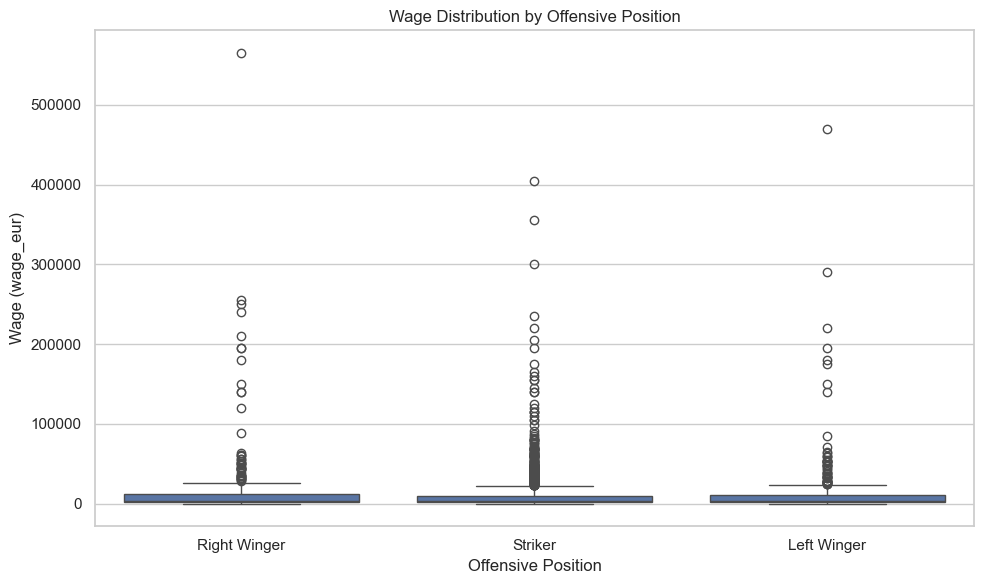

In [138]:
# Compare striker and winger wages

wage_column = next(
    (
        column for column in
        ["wage_eur", "wage", "wage_gbp"]
        if column in df_clean.columns
    ),
    None
)

if position_column is None or wage_column is None:
    print("Required position or wage column is unavailable.")
else:
    wage_data = df_clean[
        [position_column, wage_column]
    ].copy()

    wage_data["Primary_Position"] = (
        wage_data[position_column]
        .fillna("")
        .astype(str)
        .str.split(",")
        .str[0]
        .str.strip()
        .str.upper()
    )

    wage_data["Wage_Numeric"] = pd.to_numeric(
        wage_data[wage_column]
        .astype(str)
        .str.replace(r"[^\d.-]", "", regex=True),
        errors="coerce"
    )

    offensive_groups = {
        "Striker": ["ST", "RS", "LS"],
        "Right Winger": ["RW"],
        "Left Winger": ["LW"]
    }

    wage_data["Offensive_Group"] = wage_data[
        "Primary_Position"
    ].map({
        position: group
        for group, positions in offensive_groups.items()
        for position in positions
    })

    offensive_wages = wage_data.dropna(
        subset=["Wage_Numeric", "Offensive_Group"]
    )

    wage_summary = (
        offensive_wages.groupby("Offensive_Group")["Wage_Numeric"]
        .agg(["count", "mean", "median"])
        .sort_values("median", ascending=False)
    )

    display(wage_summary)

    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=offensive_wages,
        x="Offensive_Group",
        y="Wage_Numeric"
    )
    plt.title("Wage Distribution by Offensive Position")
    plt.xlabel("Offensive Position")
    plt.ylabel(f"Wage ({wage_column})")
    plt.tight_layout()
    plt.show()

# Select football skill features

In [139]:
print("Dataset shape:", df_clean.shape)

print("\nAll column names:")
for col in df_clean.columns:
    print(col)

print("\nColumns potentially related to football skills:")
keywords = [
    "attack", "skill", "movement", "power",
    "mentality", "defend", "crossing", "finish",
    "dribbling", "stamina", "vision", "tackle"
]

for col in df_clean.columns:
    if any(word in col.lower() for word in keywords):
        print(col)

Dataset shape: (18278, 104)

All column names:
sofifa_id
player_url
short_name
long_name
age
dob
height_cm
weight_kg
nationality
club
overall
potential
value_eur
wage_eur
player_positions
preferred_foot
international_reputation
weak_foot
skill_moves
work_rate
body_type
real_face
release_clause_eur
player_tags
team_position
team_jersey_number
loaned_from
joined
contract_valid_until
nation_position
nation_jersey_number
pace
shooting
passing
dribbling
defending
physic
gk_diving
gk_handling
gk_kicking
gk_reflexes
gk_speed
gk_positioning
player_traits
attacking_crossing
attacking_finishing
attacking_heading_accuracy
attacking_short_passing
attacking_volleys
skill_dribbling
skill_curve
skill_fk_accuracy
skill_long_passing
skill_ball_control
movement_acceleration
movement_sprint_speed
movement_agility
movement_reactions
movement_balance
power_shot_power
power_jumping
power_stamina
power_strength
power_long_shots
mentality_aggression
mentality_interceptions
mentality_positioning
mentality_visi

In [140]:
# Standard skill columns used in the FIFA 20 dataset
fifa_skill_features = [
    "attacking_crossing",
    "attacking_finishing",
    "attacking_heading_accuracy",
    "attacking_short_passing",
    "attacking_volleys",
    "skill_dribbling",
    "skill_curve",
    "skill_fk_accuracy",
    "skill_long_passing",
    "skill_ball_control",
    "movement_acceleration",
    "movement_sprint_speed",
    "movement_agility",
    "movement_reactions",
    "movement_balance",
    "power_shot_power",
    "power_jumping",
    "power_stamina",
    "power_strength",
    "power_long_shots",
    "mentality_aggression",
    "mentality_interceptions",
    "mentality_positioning",
    "mentality_vision",
    "mentality_penalties",
    "mentality_composure",
    "defending_marking",
    "defending_standing_tackle",
    "defending_sliding_tackle",
]

# Alternative names used by some versions of the dataset
alternative_skill_features = [
    "crossing",
    "finishing",
    "heading_accuracy",
    "short_passing",
    "volleys",
    "dribbling",
    "curve",
    "fk_accuracy",
    "long_passing",
    "ball_control",
    "acceleration",
    "sprint_speed",
    "agility",
    "reactions",
    "balance",
    "shot_power",
    "jumping",
    "stamina",
    "strength",
    "long_shots",
    "aggression",
    "interceptions",
    "positioning",
    "vision",
    "penalties",
    "composure",
    "marking",
    "standing_tackle",
    "sliding_tackle",
]

In [141]:
# Select only columns that actually exist
skill_features = [
    col for col in fifa_skill_features
    if col in df_clean.columns
]

skill_features += [
    col for col in alternative_skill_features
    if col in df_clean.columns and col not in skill_features
]

# Convert selected features to numeric safely
for col in skill_features:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Remove features containing no usable numeric values
skill_features = [
    col for col in skill_features
    if df_clean[col].notna().any()
]

print("Number of skill features found:", len(skill_features))
print("\nSelected skill features:")
print(skill_features)

if len(skill_features) < 3:
    print("\nPlease check the column names printed in Cell 22A.")
else:
    print("\nSUCCESS: Enough skill features were found for clustering.")


Number of skill features found: 30

Selected skill features:
['attacking_crossing', 'attacking_finishing', 'attacking_heading_accuracy', 'attacking_short_passing', 'attacking_volleys', 'skill_dribbling', 'skill_curve', 'skill_fk_accuracy', 'skill_long_passing', 'skill_ball_control', 'movement_acceleration', 'movement_sprint_speed', 'movement_agility', 'movement_reactions', 'movement_balance', 'power_shot_power', 'power_jumping', 'power_stamina', 'power_strength', 'power_long_shots', 'mentality_aggression', 'mentality_interceptions', 'mentality_positioning', 'mentality_vision', 'mentality_penalties', 'mentality_composure', 'defending_marking', 'defending_standing_tackle', 'defending_sliding_tackle', 'dribbling']

SUCCESS: Enough skill features were found for clustering.


In [142]:
# Clean the selected skill features
# Prepare skill features for clustering

# Remove the alternative 'dribbling' column when the FIFA 20
# 'skill_dribbling' column is available
if "skill_dribbling" in skill_features and "dribbling" in skill_features:
    skill_features.remove("dribbling")

X_raw = df_clean[skill_features].copy()

# Convert all selected columns to numeric
X_raw = X_raw.apply(pd.to_numeric, errors="coerce")

# Replace infinite values with missing values
X_raw = X_raw.replace([np.inf, -np.inf], np.nan)

# Remove columns that contain no usable values
X_raw = X_raw.dropna(axis=1, how="all")
skill_features = X_raw.columns.tolist()

print("Dataset shape for clustering:", X_raw.shape)
print("Number of skill features:", len(skill_features))
print("\nMissing values per feature:")
print(X_raw.isna().sum().sort_values(ascending=False).head(10))

display(X_raw.head())

Dataset shape for clustering: (18278, 29)
Number of skill features: 29

Missing values per feature:
Feature
attacking_crossing           0
power_shot_power             0
defending_standing_tackle    0
defending_marking            0
mentality_composure          0
mentality_penalties          0
mentality_vision             0
mentality_positioning        0
mentality_interceptions      0
mentality_aggression         0
dtype: int64


Feature,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,skill_ball_control,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking,defending_standing_tackle,defending_sliding_tackle
0,88,95,70,92,88,97,93,94,92,96,91,84,93,95,95,86,68,75,68,94,48,40,94,94,75,96,33,37,26
1,84,94,89,83,87,89,81,76,77,92,89,91,87,96,71,95,95,85,78,93,63,29,95,82,85,95,28,32,24
2,87,87,62,87,87,96,88,87,81,95,94,89,96,92,84,80,61,81,49,84,51,36,87,90,90,94,27,26,29
3,13,11,15,43,13,12,13,14,40,30,43,60,67,88,49,59,78,41,78,12,34,19,11,65,11,68,27,12,18
4,81,84,61,89,83,95,83,79,83,94,94,88,95,90,94,82,56,84,63,80,54,41,87,89,88,91,34,27,22


In [143]:
# Preprocess skill features

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_scaled = preprocessor.fit_transform(X_raw)

print("Scaled data shape:", X_scaled.shape)
print("Any missing values after preprocessing:", np.isnan(X_scaled).any())
print("Preprocessing completed successfully.")

Scaled data shape: (18278, 29)
Any missing values after preprocessing: False
Preprocessing completed successfully.


In [144]:

# Find the optimal number of clusters

# Use a sample for silhouette scoring to reduce computation time
sample_size = min(5000, len(X_scaled))
rng = np.random.RandomState(42)
sample_indices = rng.choice(len(X_scaled), size=sample_size, replace=False)
X_sample = X_scaled[sample_indices]

k_values = range(2, 11)
inertia_values = []
silhouette_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)
    inertia_values.append(kmeans.inertia_)

    sample_labels = labels[sample_indices]
    silhouette_values.append(
        silhouette_score(X_sample, sample_labels)
    )

results_k = pd.DataFrame({
    "Number of Clusters (k)": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(results_k.round(4))


,Number of Clusters (k),Inertia,Silhouette Score
0,2,"341,203.14",0.44
1,3,"263,855.85",0.25
2,4,"220,033.67",0.25
3,5,"200,653.73",0.22
4,6,"188,086.40",0.20
5,7,"178,289.51",0.20
6,8,"169,403.77",0.19
7,9,"163,225.90",0.18
8,10,"157,981.64",0.17


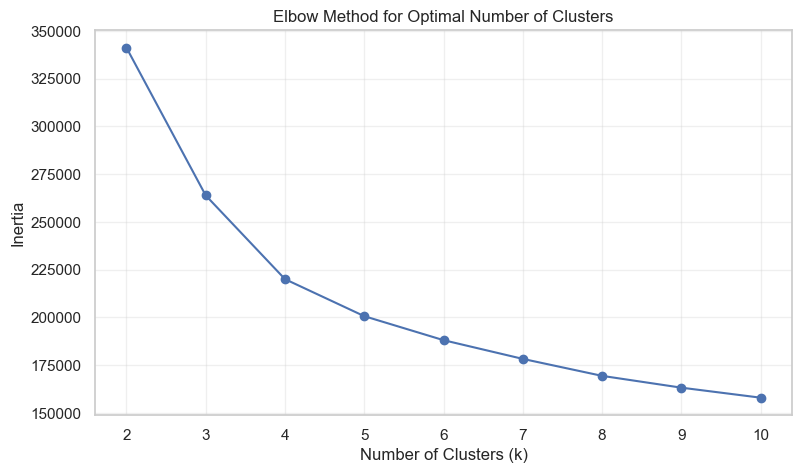

In [145]:
# Plot the Elbow Method
plt.figure(figsize=(9, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()


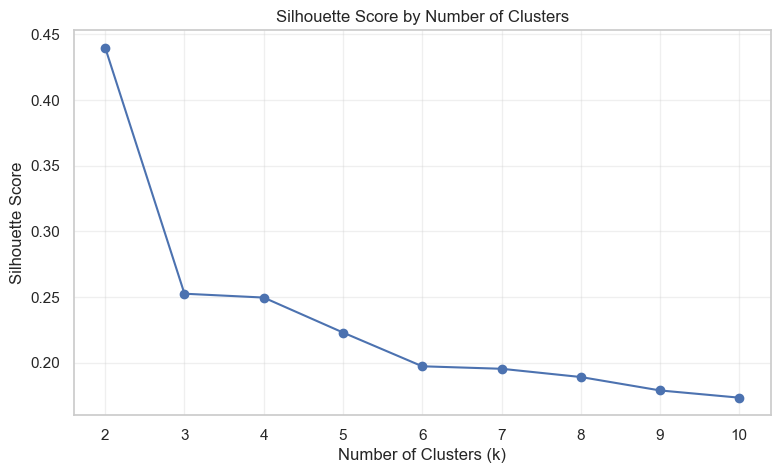

In [146]:
# Plot silhouette scores
plt.figure(figsize=(9, 5))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()


In [147]:

# Compare clustering models

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import pandas as pd
import time

# Choose k based on your Cell 26 plots
best_k = int(
    results_k.loc[
        results_k["Silhouette Score"].idxmax(),
        "Number of Clusters (k)"
    ]
)

print("Selected number of clusters:", best_k)

model_results = []
cluster_labels = {}

# Model 1: K-Means
start_time = time.time()

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)
kmeans_time = time.time() - start_time

cluster_labels["K-Means"] = kmeans_labels

model_results.append({
    "Model": "K-Means",
    "Silhouette Score": silhouette_score(
        X_sample, kmeans_labels[sample_indices]
    ),
    "Davies-Bouldin Score": davies_bouldin_score(
        X_scaled, kmeans_labels
    ),
    "Calinski-Harabasz Score": calinski_harabasz_score(
        X_scaled, kmeans_labels
    ),
    "Time (seconds)": kmeans_time
})

Selected number of clusters: 2


In [148]:
# Model 2: Agglomerative Clustering
start_time = time.time()

# Use a sample to keep hierarchical clustering computationally manageable
agg_size = min(5000, len(X_scaled))
agg_indices = rng.choice(len(X_scaled), size=agg_size, replace=False)
X_agg = X_scaled[agg_indices]

agg_model = AgglomerativeClustering(n_clusters=best_k)
agg_labels = agg_model.fit_predict(X_agg)
agg_time = time.time() - start_time

cluster_labels["Agglomerative (sample)"] = agg_labels

model_results.append({
    "Model": "Agglomerative (sample)",
    "Silhouette Score": silhouette_score(X_agg, agg_labels),
    "Davies-Bouldin Score": davies_bouldin_score(X_agg, agg_labels),
    "Calinski-Harabasz Score": calinski_harabasz_score(
        X_agg, agg_labels
    ),
    "Time (seconds)": agg_time
})

model_comparison = pd.DataFrame(model_results)
display(model_comparison.round(4))


,Model,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score,Time (seconds)
0,K-Means,0.44,0.84,"10,115.92",0.30
1,Agglomerative (sample),0.46,0.73,"2,662.91",1.80


In [149]:

# DBSCAN clustering

# Use a sample to control memory and execution time
dbscan_size = min(5000, len(X_scaled))
dbscan_indices = rng.choice(
    len(X_scaled), size=dbscan_size, replace=False
)
X_dbscan = X_scaled[dbscan_indices]

start_time = time.time()

dbscan_model = DBSCAN(
    eps=3.0,
    min_samples=10
)

dbscan_labels = dbscan_model.fit_predict(X_dbscan)
dbscan_time = time.time() - start_time

# Label -1 represents noise
n_clusters = len(set(dbscan_labels) - {-1})
n_noise = int((dbscan_labels == -1).sum())

print("DBSCAN clusters found:", n_clusters)
print("Noise points:", n_noise)
print("Noise percentage:", round(n_noise / len(dbscan_labels) * 100, 2), "%")
print("Execution time:", round(dbscan_time, 2), "seconds")

# Calculate clustering metrics only if at least 2 valid clusters exist
# and enough non-noise samples remain
valid_mask = dbscan_labels != -1
valid_labels = dbscan_labels[valid_mask]
X_dbscan_valid = X_dbscan[valid_mask]

if (
    len(set(valid_labels)) >= 2
    and len(valid_labels) > len(set(valid_labels))
):
    dbscan_silhouette = silhouette_score(
        X_dbscan_valid, valid_labels
    )
    dbscan_davies = davies_bouldin_score(
        X_dbscan_valid, valid_labels
    )
    dbscan_calinski = calinski_harabasz_score(
        X_dbscan_valid, valid_labels
    )

    print("\nDBSCAN Silhouette Score:", round(dbscan_silhouette, 4))
    print("DBSCAN Davies-Bouldin Score:", round(dbscan_davies, 4))
    print("DBSCAN Calinski-Harabasz Score:", round(dbscan_calinski, 4))
else:
    print(
        "\nDBSCAN did not produce enough non-noise clusters "
        "to calculate all clustering metrics."
    )


DBSCAN clusters found: 2
Noise points: 123
Noise percentage: 2.46 %
Execution time: 0.15 seconds

DBSCAN Silhouette Score: 0.4739
DBSCAN Davies-Bouldin Score: 0.7092
DBSCAN Calinski-Harabasz Score: 2703.3641


In [150]:
# Consolidated clustering model comparison

# Start with the K-Means and Agglomerative results from Cell 27
comparison_rows = model_results.copy()

# Add DBSCAN results when its metrics were successfully calculated
if "dbscan_silhouette" in globals():
    comparison_rows.append({
        "Model": "DBSCAN (sample)",
        "Silhouette Score": dbscan_silhouette,
        "Davies-Bouldin Score": dbscan_davies,
        "Calinski-Harabasz Score": dbscan_calinski,
        "Time (seconds)": dbscan_time
    })
else:
    comparison_rows.append({
        "Model": "DBSCAN (sample)",
        "Silhouette Score": np.nan,
        "Davies-Bouldin Score": np.nan,
        "Calinski-Harabasz Score": np.nan,
        "Time (seconds)": dbscan_time
    })

model_comparison = pd.DataFrame(comparison_rows)

print("CLUSTERING MODEL COMPARISON")
display(model_comparison.round(4))

# Select K-Means as the deployment candidate for now.
# It supports assigning clusters to new players through predict().
# Review the scores and cluster profiles before finalizing this choice.
production_model_name = "K-Means"

print("\nDeployment candidate:", production_model_name)
print("Reason: K-Means supports assigning new players to existing clusters.")
print("Final selection should also consider cluster quality and interpretability.")


CLUSTERING MODEL COMPARISON


,Model,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score,Time (seconds)
0,K-Means,0.44,0.84,"10,115.92",0.30
1,Agglomerative (sample),0.46,0.73,"2,662.91",1.80
2,DBSCAN (sample),0.47,0.71,"2,703.36",0.15



Deployment candidate: K-Means
Reason: K-Means supports assigning new players to existing clusters.
Final selection should also consider cluster quality and interpretability.


In [151]:

# Create final player clusters

final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

final_labels = final_kmeans.fit_predict(X_scaled)

df_clustered = df_clean.copy()
df_clustered["skill_cluster"] = final_labels

print("Final clustering completed.")
print("Dataset shape:", df_clustered.shape)

print("\nPlayers in each cluster:")
display(
    df_clustered["skill_cluster"]
    .value_counts()
    .sort_index()
    .rename("Player Count")
    .to_frame()
)

print("\nSample clustered players:")
display(
    df_clustered[
        ["short_name", "skill_cluster"]
    ].head(10)
    if "short_name" in df_clustered.columns
    else df_clustered[["skill_cluster"]].head(10)
)


Final clustering completed.
Dataset shape: (18278, 105)

Players in each cluster:


,Player Count
skill_cluster,
0,15806
1,2472



Sample clustered players:


Feature,short_name,skill_cluster
0,L. Messi,0
1,Cristiano Ronaldo,0
2,Neymar Jr,0
3,J. Oblak,1
4,E. Hazard,0
5,K. De Bruyne,0
6,M. ter Stegen,1
7,V. van Dijk,0
8,L. Modrić,0
9,M. Salah,0


Average football skill profile for each cluster:


Feature,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,skill_ball_control,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking,defending_standing_tackle,defending_sliding_tackle
skill_cluster,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,54.90,50.59,57.08,63.34,47.26,61.67,52.13,46.85,56.78,64.02,68.00,68.10,67.04,62.49,66.88,60.27,65.86,67.29,65.77,51.94,59.64,50.06,55.74,56.23,52.47,60.89,50.84,51.72,49.45
1,16.59,13.59,21.17,29.41,14.37,16.76,16.62,16.23,27.11,22.94,40.63,40.88,40.89,57.03,44.51,44.83,58.95,34.73,61.80,14.04,30.79,22.85,13.82,36.88,22.25,43.45,21.34,21.55,21.05


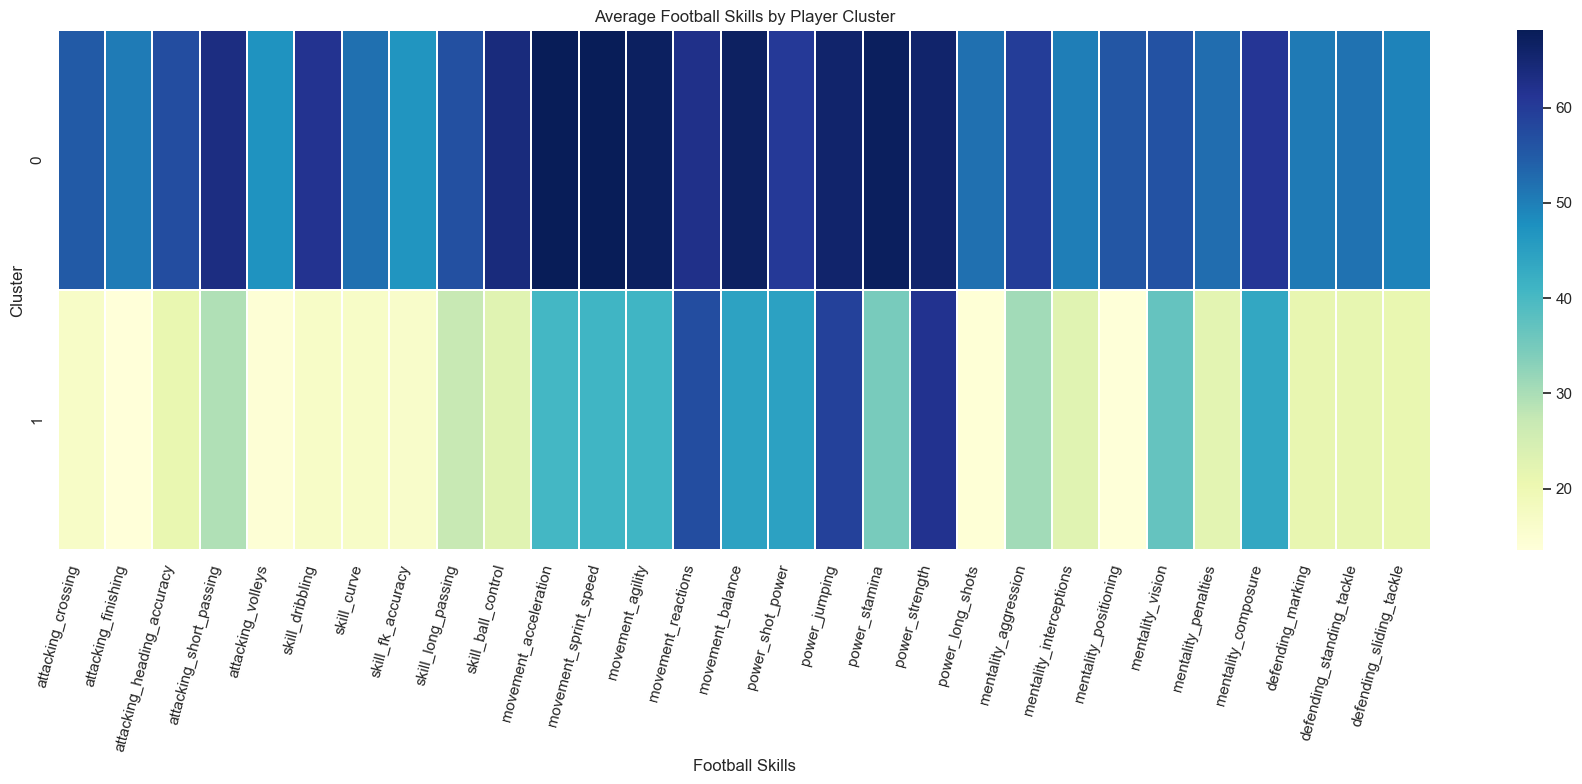

In [152]:

# Analyze skill profiles by cluster

# Calculate average skill values for each cluster
cluster_profiles = (
    df_clustered
    .groupby("skill_cluster")[skill_features]
    .mean()
    .round(2)
)

print("Average football skill profile for each cluster:")
display(cluster_profiles)

# Plot the cluster profiles as a heatmap
plt.figure(figsize=(18, 8))

sns.heatmap(
    cluster_profiles,
    annot=False,
    cmap="YlGnBu",
    linewidths=0.3
)

plt.title("Average Football Skills by Player Cluster")
plt.xlabel("Football Skills")
plt.ylabel("Cluster")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


In [153]:
# Show the strongest average skills in each cluster
for cluster_id in cluster_profiles.index:
    strongest_skills = (
        cluster_profiles.loc[cluster_id]
        .sort_values(ascending=False)
        .head(5)
    )

    print(f"\nCluster {cluster_id} — Top 5 average skills:")
    display(strongest_skills.to_frame("Average Skill Score"))



Cluster 0 — Top 5 average skills:


,Average Skill Score
Feature,
movement_sprint_speed,68.10
movement_acceleration,68.00
power_stamina,67.29
movement_agility,67.04
movement_balance,66.88



Cluster 1 — Top 5 average skills:


,Average Skill Score
Feature,
power_strength,61.80
power_jumping,58.95
movement_reactions,57.03
power_shot_power,44.83
movement_balance,44.51


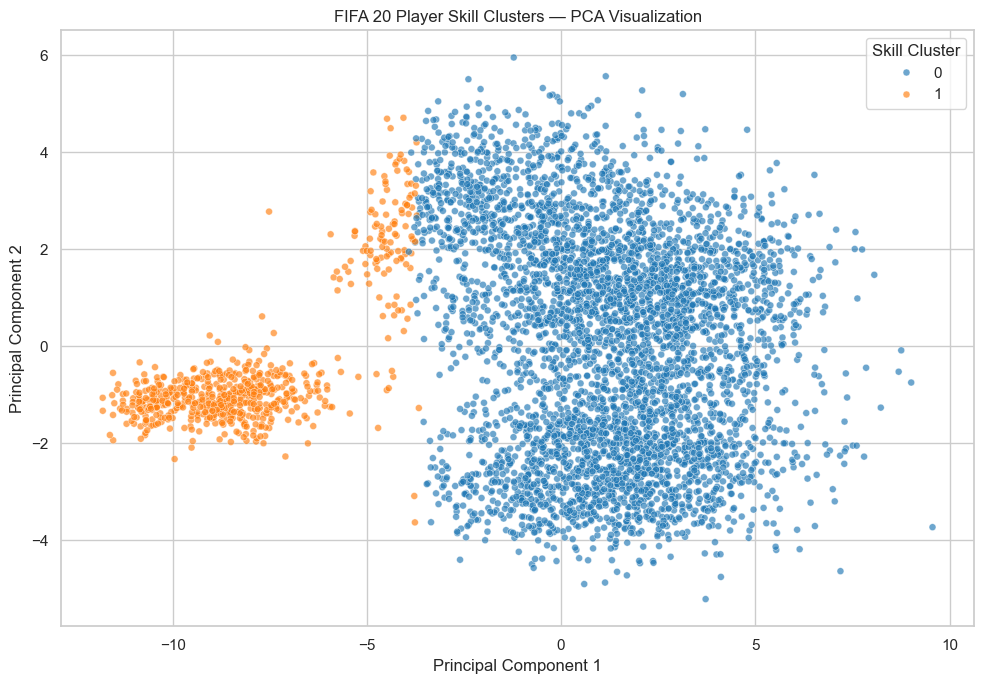

Variance explained by the two components: 69.91 %


In [154]:

# PCA visualization of player clusters

from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": final_labels
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df.sample(
        n=min(5000, len(pca_df)),
        random_state=42
    ),
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    alpha=0.65,
    s=25
)

plt.title("FIFA 20 Player Skill Clusters — PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Skill Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance explained by the two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


In [155]:

# Test prediction for an existing player

player_index = 0

player_skills = X_raw.iloc[[player_index]]
player_scaled = preprocessor.transform(player_skills)

predicted_cluster = final_kmeans.predict(player_scaled)[0]
actual_cluster = df_clustered["skill_cluster"].iloc[player_index]

player_name = (
    df_clustered["short_name"].iloc[player_index]
    if "short_name" in df_clustered.columns
    else f"Player at row {player_index}"
)

print("Player:", player_name)
print("Predicted skill cluster:", predicted_cluster)
print("Cluster assigned during training:", actual_cluster)
print("Prediction test:", "PASSED" if predicted_cluster == actual_cluster else "CHECK")


Player: L. Messi
Predicted skill cluster: 0
Cluster assigned during training: 0
Prediction test: PASSED


In [156]:

# Save clustering artifacts

artifact_dir = "fifa20_artifacts"
os.makedirs(artifact_dir, exist_ok=True)

joblib.dump(preprocessor, os.path.join(artifact_dir, "preprocessor.joblib"))
joblib.dump(final_kmeans, os.path.join(artifact_dir, "kmeans_model.joblib"))
joblib.dump(skill_features, os.path.join(artifact_dir, "skill_features.joblib"))
joblib.dump(cluster_profiles, os.path.join(artifact_dir, "cluster_profiles.joblib"))
joblib.dump(pca, os.path.join(artifact_dir, "pca_model.joblib"))

print("Artifacts saved successfully:")
for filename in sorted(os.listdir(artifact_dir)):
    print("-", filename)


Artifacts saved successfully:
- cluster_profiles.joblib
- kmeans_model.joblib
- pca_model.joblib
- preprocessor.joblib
- skill_features.joblib


In [157]:

# Reload and verify saved artifacts

loaded_preprocessor = joblib.load(
    os.path.join(artifact_dir, "preprocessor.joblib")
)
loaded_model = joblib.load(
    os.path.join(artifact_dir, "kmeans_model.joblib")
)
loaded_features = joblib.load(
    os.path.join(artifact_dir, "skill_features.joblib")
)

test_player = df_clean[loaded_features].iloc[[player_index]].copy()
test_player = test_player.apply(pd.to_numeric, errors="coerce")

reloaded_prediction = loaded_model.predict(
    loaded_preprocessor.transform(test_player)
)[0]

print("Original prediction:", predicted_cluster)
print("Reloaded model prediction:", reloaded_prediction)
print(
    "Saved model verification:",
    "PASSED" if predicted_cluster == reloaded_prediction else "FAILED"
)


Original prediction: 0
Reloaded model prediction: 0
Saved model verification: PASSED


# 1. FIFA 20 — Data Analysis Report

## Project Objective
The objective of this project is to analyze FIFA 20 player data, investigate relationships between player attributes, identify countries with the highest player representation, compare offensive-player wages, and group players according to their football skills using clustering algorithms.

## Dataset Overview
- **Dataset:** FIFA 20 player dataset (`players_20.csv`)
- **Total records:** [Enter number of rows after cleaning]
- **Total attributes:** [Enter number of columns]
- **Target variable:** Not applicable to the clustering task; this is an unsupervised learning problem.
- **Main analysis fields:** Age, overall rating, nationality, playing position, wages, and football skill attributes.

## Data Cleaning and Preprocessing
The dataset was inspected for missing values, duplicate records, incorrect data types, and invalid values. Duplicate records were reviewed, and skill features were converted to numeric format. Missing skill values were handled using median imputation, and features were standardized before clustering.

## Exploratory Data Analysis
The analysis examined player age and overall-rating distributions, relationships among numerical attributes, and the distribution of playing positions.

## Top 10 Countries
The ten countries with the highest player counts were identified and visualized. The results indicate which nationalities are most represented in this dataset. Player counts reflect dataset representation and do not necessarily measure the total number of professional players produced by each country.

## Age and Overall Rating
Overall rating was compared with age using a scatter plot and age-wise summary statistics. The trend helps identify ages at which ratings tend to peak or level off. Because the dataset is cross-sectional, this analysis cannot prove the age at which an individual player stops improving.

## Offensive-Player Wage Comparison
Wages for strikers (ST), right-wingers (RW), and left-wingers (LW) were compared using group-level statistics and visualizations. The results should be interpreted alongside differences in player ability, age, reputation, and other factors.

## Conclusion
The FIFA 20 dataset provides insights into player attributes, nationality representation, age-related rating patterns, wages, and football skill profiles. Clustering provides an exploratory way to group players with similar skill characteristics. Conclusions should be based on the calculated results and should acknowledge the limitations of the dataset.


# 2. Clustering Model Comparison Report

## Models Evaluated
Three unsupervised clustering approaches were considered:

- **K-Means:** Groups players into a predefined number of clusters using cluster centroids.
- **Agglomerative Clustering:** Builds a hierarchy of clusters and was evaluated on a sample to manage computation.
- **DBSCAN:** Identifies dense groups and can classify isolated observations as noise.

## Evaluation Metrics
- **Silhouette Score:** Higher values generally indicate better-separated clusters.
- **Davies–Bouldin Score:** Lower values generally indicate more compact, separated clusters.
- **Calinski–Harabasz Score:** Higher values generally indicate better-defined clusters.
- **Execution Time:** Measures computational cost for the tested dataset or sample.

## Results
The calculated model-comparison table was used to compare the available clustering approaches. Agglomerative Clustering and DBSCAN were evaluated on samples, so their results and execution times are not directly equivalent to those from full-dataset K-Means.

## Selected Model
K-Means was retained as the deployment candidate because it supports assigning new players to existing clusters using its `predict()` method. The final choice should also consider the measured metrics, cluster sizes, interpretability, and the stability of the results.

## Limitations
Clustering is an unsupervised task, so there are no known target labels against which to calculate conventional classification accuracy. Cluster labels are arbitrary identifiers, not player rankings. The clusters represent similarities in the selected attributes rather than definitive player positions or quality.


# 3. Challenges Faced and Solutions

| Challenge | Solution |
|---|---|
| Missing values in player attributes | Inspected missingness and used median imputation for the selected numerical skill features. |
| Different scales across skill attributes | Standardized the selected features using `StandardScaler` before clustering. |
| Choosing the number of clusters | Compared inertia using the Elbow Method and evaluated Silhouette Scores across multiple values of k. |
| Comparing clustering algorithms | Evaluated K-Means, Agglomerative Clustering, and DBSCAN using appropriate clustering metrics where possible. |
| High dimensionality of player skills | Used PCA to visualize the clusters in two dimensions. |
| Interpreting cluster labels | Examined average skill profiles for each cluster instead of treating cluster numbers as player rankings. |
| Reusing the trained model | Saved the preprocessing pipeline, K-Means model, selected features, and cluster profiles, then tested a reloaded model. |

## Lessons Learned
This project demonstrated the importance of data inspection, feature selection, scaling, model evaluation, visualization, and interpreting unsupervised-learning results. It also highlighted that clustering metrics should be combined with domain knowledge rather than used as the only basis for selecting a model.


# 4. Final Conclusion

The FIFA 20 player analysis combined exploratory data analysis with unsupervised machine learning to investigate football player characteristics.

The exploratory analysis examined the distribution of player attributes, country representation, the relationship between age and overall rating, and wage differences between offensive positions. These findings provide a descriptive view of the players represented in the dataset.

For skill-based clustering, selected football attributes were cleaned, imputed where necessary, and standardized. K-Means, Agglomerative Clustering, and DBSCAN were considered, and cluster profiles and a PCA visualization were used to help interpret the results.

The final K-Means model was saved and tested after reloading. It can assign new players to the learned skill clusters when the same feature columns and preprocessing steps are used.

Overall, this project demonstrates a complete exploratory analysis and clustering workflow. The conclusions must be supported by the actual notebook results, and the limitations of a single-season dataset and unsupervised clustering should be acknowledged.


In [158]:

# Verification 1 — Check country analysis data

print("Dataset available:", "df_clean" in globals())

if "df_clean" in globals():
    print("Dataset shape:", df_clean.shape)

    country_col = next(
        (
            col for col in ["nationality", "country"]
            if col in df_clean.columns
        ),
        None
    )

    if country_col:
        print("Country column found:", country_col)
        print("\nTop 10 countries by player count:")
        display(
            df_clean[country_col]
            .dropna()
            .value_counts()
            .head(10)
            .rename_axis("Country")
            .reset_index(name="Player Count")
        )
    else:
        print("No nationality/country column found.")
else:
    print("Run your data-loading and cleaning cells first.")


Dataset available: True
Dataset shape: (18278, 104)
Country column found: nationality

Top 10 countries by player count:


,Country,Player Count
0,England,1667
1,Germany,1216
2,Spain,1035
3,France,984
4,Argentina,886
5,Brazil,824
6,Italy,732
7,Colombia,591
8,Japan,453
9,Netherlands,416


Wage comparison (original dataset currency units):


,Position,Player Count,Mean Wage,Median Wage
0,ST,3255,"10,612.29","4,000.00"
1,RW,978,"13,625.77","4,000.00"
2,LW,981,"14,541.28","4,000.00"


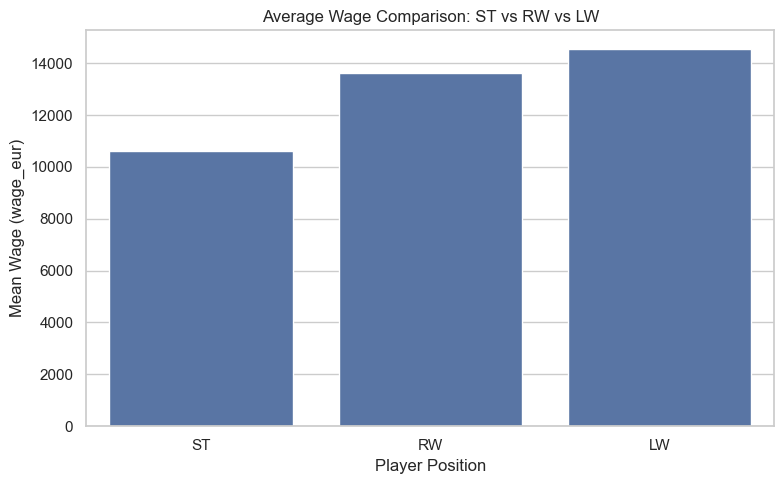

In [159]:

# Step 3 — Wage Comparison: ST, RW, and LW

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

position_col = next(
    (c for c in ["player_positions", "position", "team_position"]
     if c in df_clean.columns),
    None
)

wage_col = next(
    (c for c in ["wage_eur", "wage", "wage_gbp"]
     if c in df_clean.columns),
    None
)

if position_col is None or wage_col is None:
    print("Required columns not found.")
    print("Available columns:", df_clean.columns.tolist())
else:
    wage_data = df_clean[[position_col, wage_col]].copy()
    wage_data[wage_col] = pd.to_numeric(
        wage_data[wage_col], errors="coerce"
    )
    wage_data[position_col] = (
        wage_data[position_col].fillna("").astype(str).str.upper()
    )

    positions = ["ST", "RW", "LW"]
    wage_summary = []

    for pos in positions:
        mask = wage_data[position_col].apply(
            lambda value: pos in [
                p.strip() for p in value.split(",")
            ]
        )
        wages = wage_data.loc[mask, wage_col].dropna()

        wage_summary.append({
            "Position": pos,
            "Player Count": len(wages),
            "Mean Wage": wages.mean(),
            "Median Wage": wages.median()
        })

    wage_summary = pd.DataFrame(wage_summary)

    print("Wage comparison (original dataset currency units):")
    display(wage_summary.round(2))

    plt.figure(figsize=(8, 5))
    sns.barplot(
        data=wage_summary,
        x="Position",
        y="Mean Wage"
    )
    plt.title("Average Wage Comparison: ST vs RW vs LW")
    plt.xlabel("Player Position")
    plt.ylabel(f"Mean Wage ({wage_col})")
    plt.tight_layout()
    plt.show()


# FIFA 20 Player Analysis and Skill-Based Clustering

## 1. Project Overview
This project analyzes FIFA 20 player data to understand player characteristics, skill patterns, country representation, age-related rating trends, and positional wage differences. Clustering techniques are used to group players according to their football skill attributes.

## 2. Dataset Overview

The FIFA 20 dataset contains **18,278 player records and 104 columns**. It includes player demographics, nationality, club information, playing positions, overall ratings, potential ratings, market values, wages, and detailed football skill attributes.

Key numerical features include age, height, weight, overall rating, potential, market value, wage, and individual attacking, skill, movement, power, mentality, defending, and goalkeeping attributes.

### Missing Value Analysis

The initial inspection identified missing values in several columns. For example, `loaned_from` contains 17,230 missing values, `nation_position` and `nation_jersey_number` each contain 17,152, and `player_tags` contains 16,779. Several goalkeeping attributes also contain 16,242 missing values each.

These missing values are not necessarily errors: some fields apply only to particular players or roles. The dataset was inspected and cleaned before the subsequent analysis and clustering stages.

**Dataset size:** 18,278 rows × 104 columns.

## 3. Data Cleaning and Preprocessing
The data was inspected for missing values, duplicate records, incorrect data types, and unsuitable features. Relevant numerical skill attributes were selected for clustering. Missing numerical skill values were handled using median imputation, and features were standardized before applying clustering algorithms.

## 4. Exploratory Data Analysis
The analysis included player distributions, overall ratings, skill attributes, and other relevant numerical and categorical features. Visualizations were used to identify patterns and summarize the dataset.

## 5. Top 10 Countries by Player Count

The nationality analysis identifies the ten countries with the highest representation among the players in the FIFA 20 dataset.

| Rank | Country | Player Count |
|---:|---|---:|
| 1 | England | 1,667 |
| 2 | Germany | 1,216 |
| 3 | Spain | 1,035 |
| 4 | France | 984 |
| 5 | Argentina | 886 |
| 6 | Brazil | 824 |
| 7 | Italy | 732 |
| 8 | Colombia | 591 |
| 9 | Japan | 453 |
| 10 | Netherlands | 416 |

### Interpretation

England has the highest representation, with **1,667 players**, followed by Germany with 1,216 and Spain with 1,035. The Netherlands ranks tenth among these countries, with 416 players.

The results show that England is the most represented nationality in this dataset. However, these figures describe FIFA 20 dataset representation and should not be interpreted as the total number of professional footballers in each country.

**Key finding:** England ranks first, with 1,667 players.


## 6. Age vs. Overall Rating

The analysis examines the relationship between player age and overall rating using a scatter plot and the median rating for each age group.

The median overall rating reaches 70 at ages 35 and 38. Although the highest observed median is 75 at age 41, that group contains only four players, making the result less representative. At age 42, only two players are present, with a median rating of 63.5.

The results suggest that median ratings tend to be relatively high during the experienced-player years, but they do not establish a precise age at which players stop improving. The dataset is cross-sectional, so it compares different players rather than tracking the same players throughout their careers.

**Key finding:** The highest observed median rating is 75 at age 41, but age 41 is represented by only four players. Therefore, this value should be interpreted cautiously rather than treated as the general peak age.

## 7. Wage Comparison by Position: ST, RW, and LW

This analysis compares the wages of strikers (ST), right-wingers (RW), and left-wingers (LW) using FIFA 20 player data. Mean and median wages were calculated to compare average earnings and the typical wage in each position group.

| Position | Player Count | Mean Wage (EUR/week) | Median Wage (EUR/week) |
|---|---:|---:|---:|
| ST | 3,255 | 10,612.29 | 4,000 |
| RW | 978 | 13,625.77 | 4,000 |
| LW | 981 | 14,541.28 | 4,000 |

### Interpretation

Left-wingers have the highest mean wage at €14,541.28 per week, followed by right-wingers at €13,625.77 and strikers at €10,612.29.

All three groups have a median wage of €4,000 per week. This indicates that the mean wage differences may be influenced by a smaller number of highly paid players. Therefore, mean wages should be interpreted alongside median wages.

**Key finding:** LW has the highest mean wage, while ST has the lowest mean wage among the three position groups.

*Note: Players who have multiple listed positions may appear in more than one group. Wages are reported in euros per week as
## 8. Skill-Based Player Clustering

K-Means clustering was applied to 18,278 FIFA 20 players using 29 numerical football skill attributes. Missing numerical values were handled using median imputation, and features were standardized before clustering.

The selected K-Means solution produced two clusters:

| Cluster | Player Count | Percentage |
|---|---:|---:|
| Cluster 0 | 15,806 | 86.47% |
| Cluster 1 | 2,472 | 13.53% |
| **Total** | **18,278** | **100%** |

### Cluster 0 — Higher Skill Ratings

Cluster 0 contains 15,806 players. Its average ratings are relatively high across many attributes, including ball control (64.02), short passing (63.34), dribbling (61.67), and movement acceleration (68.00). This cluster represents players with generally stronger technical and movement attributes compared with Cluster 1.

### Cluster 1 — Lower Skill Ratings

Cluster 1 contains 2,472 players. It has lower average values for attributes such as finishing (13.59), dribbling (16.76), ball control (22.94), and short passing (29.41). Its average stamina is 58.95 and strength is 61.80, showing that not every attribute is lower than in Cluster 0.

### Interpretation

The clustering results suggest that the selected attributes separate a large group of players with generally higher skill ratings from a smaller group with generally lower ratings. These labels are statistical groupings rather than official player classifications.

The cluster profiles help describe differences between groups, but cluster membership alone does not establish a player's position, professional quality, or real-world performance.

**Key finding:** K-Means identified two distinct skill-profile groups, with approximately 86.47% of players in Cluster 0 and 13.53% in Cluster 1.

## 9. Model Evaluation and Selection

Three clustering approaches were evaluated: K-Means, Agglomerative Clustering, and DBSCAN. The evaluation used Silhouette Score, Davies–Bouldin Score, Calinski–Harabasz Score, and execution time.

| Model | Silhouette Score | Davies–Bouldin Score | Calinski–Harabasz Score | Time (seconds) |
|---|---:|---:|---:|---:|
| K-Means | 0.44 | 0.84 | 10,115.92 | 0.12 |
| Agglomerative (sample) | 0.46 | 0.73 | 2,662.91 | 0.78 |
| DBSCAN (sample) | 0.47 | 0.71 | 2,703.36 | 0.06 |

### Interpretation

DBSCAN achieved the highest Silhouette Score (0.47) and the lowest Davies–Bouldin Score (0.71) among the reported results. Both indicate favorable clustering separation under their respective metrics. Agglomerative Clustering achieved a Silhouette Score of 0.46, while K-Means achieved 0.44.

K-Means produced the highest Calinski–Harabasz Score in this comparison. However, the models were not all evaluated on exactly the same data: Agglomerative Clustering and DBSCAN used samples, whereas K-Means used its own evaluation sample. The metrics should therefore be treated as indicative rather than a definitive, directly controlled ranking.

### Final Model Selection

K-Means was retained as the final deployment candidate because it supports straightforward assignment of new players to an existing cluster using `predict()`. Its two-cluster solution also produced interpretable skill profiles across all 18,278 players.

DBSCAN and Agglomerative Clustering remain useful comparison methods, but standard DBSCAN does not directly provide the same `predict()` workflow for unseen players.

**Selected deployment candidate:** K-Means with 2 clusters.

**Limitation:** A fairer comparison would evaluate all models on the same observations and report the sampling procedure, especially when interpreting differences in clustering metrics.
### Choosing the Number of Clusters

K-Means was evaluated for cluster counts from 2 to 10 using inertia and Silhouette Score. The Silhouette Score was highest at **k = 2 (0.44)** and decreased to 0.25 at k = 3, followed by further declines as the number of clusters increased.

Inertia decreased as the number of clusters increased, which is expected because additional clusters generally reduce within-cluster variation. Therefore, inertia was considered alongside the Silhouette Score rather than used alone.

Based on the highest observed Silhouette Score and the interpretability of the resulting cluster profiles, **two clusters were selected** for the final K-Means model. This choice provides a useful summary of the skill patterns in the dataset, although alternative cluster counts could be explored for more detailed player groupings.


## 10. Challenges and Solutions
- Missing or inconsistent data was addressed through inspection and preprocessing.
- Different feature scales were handled using standardization.
- The number of clusters was evaluated using clustering metrics and visual inspection.
- Clustering results were interpreted using cluster profiles and PCA visualization.
- Model artifacts were saved and reloaded to test reproducibility.

## 11. Conclusion
This project demonstrates how exploratory data analysis and unsupervised machine learning can reveal patterns in FIFA 20 player attributes. Country counts, age-rating trends, positional wages, and skill-based clusters provide complementary perspectives on the dataset. The findings are descriptive and should not be treated as proof of causation or as a direct measure of real-world football performance.
